# Backpropagation
## A tutorial with MoleculeNet Blood Brain Barrier Permeability

**Question:** Can a neural network learn to classify molecules by their blood–brain barrier permeability label from their structures?

We use **BBBP**, a binary classification benchmark in MoleculeNet. Each molecule is represented by a SMILES string and the `p_np` label. We convert each structure into a Morgan fingerprint, then train a small PyTorch multilayer perceptron (MLP).

### Learning goals
- Explain the forward pass, classification loss, gradient, and weight update.
- Trace one training example through a small neural network.
- Use PyTorch autograd to calculate gradients.
- Train and evaluate a molecular classifier with a scaffold split.
- Interpret benchmark results cautiously in a biomedical setting.

> This is a teaching benchmark exercise. BBBP labels are experimental dataset labels, not a clinical guarantee of brain exposure, safety, or therapeutic efficacy.

## 1. Set up the notebook

This notebook uses PyTorch for the neural network, RDKit for molecular structures and scaffold grouping, and scikit-learn for evaluation metrics. If PyTorch installation fails on your computer, use the selector on the [official PyTorch install page](https://pytorch.org/get-started/locally/) for your operating system and hardware, then rerun the imports.

In [9]:
%pip install torch rdkit scikit-learn pandas matplotlib torchinfo

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 552.4/552.4 kB 4.9 MB/s  0:00:00


In [10]:
import copy, random, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from rdkit import Chem, DataStructs
from rdkit.Chem import AllChem
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.metrics import roc_auc_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__, '| device:', device)

/usr/local/lib/python3.13/dist-packages/deepchem/feat/smiles_tokenizer.py:8: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING W&B installed but not logged in.  Run `wandb login` or set the WANDB_API_KEY env variable.
Instructions for updating:
experimental_relax_shapes is deprecated, use reduce_retracing instead
wandb: WARNING W&B installed but not logged in.  Run `wandb login` or set the WANDB_API_KEY env variable.


PyTorch: 2.11.0+cpu | device: cpu


## 2. Load the MoleculeNet BBBP table

The official DeepChem loader identifies BBBP as a binary barrier-permeability dataset with over 2,000 compounds and recommends a scaffold split. Here we download its raw CSV directly, then implement the featurization and split ourselves so each step stays visible. [Dataset loader and source URL](https://github.com/deepchem/deepchem/blob/master/deepchem/molnet/load_function/bbbp_datasets.py).

In [11]:
csv_path = Path('BBBP.csv')
url = 'https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/BBBP.csv'
if not csv_path.exists():
    urllib.request.urlretrieve(url, csv_path)
df = pd.read_csv(csv_path)
print('Rows and columns:', df.shape)
print('Columns:', df.columns.tolist())
df.head()

Rows and columns: (2050, 4)
Columns: ['num', 'name', 'p_np', 'smiles']


,num,name,p_np,smiles
0,1,Propanolol,1,[Cl].CC(C)NCC(O)COc1cccc2ccccc12
1,2,Terbutylchlorambucil,1,C(=O)(OC(C)(C)C)CCCc1ccc(cc1)N(CCCl)CCCl
2,3,40730,1,c12c3c(N4CCN(C)CC4)c(F)cc1c(c(C(O)=O)cn2C(C)CO...
3,4,24,1,C1CCN(CC1)Cc1cccc(c1)OCCCNC(=O)C
4,5,cloxacillin,1,Cc1onc(c2ccccc2Cl)c1C(=O)N[C@H]3[C@H]4SC(C)(C)...


The columns we need are `smiles` (molecular structure) and `p_np` (binary permeability label). We remove rows with missing labels or invalid SMILES. We keep the original SMILES to group related molecules by scaffold before splitting.

In [12]:
required = {'smiles', 'p_np'}
missing = required - set(df.columns)

if missing:
  raise ValueError(f'Missing expected columns: {missing}')

clean = df.dropna(subset=['smiles','p_np']).copy() # Drop rows with missing labels or smiles

# Convert to mol and drop instances not coverted to mol
clean['mol'] = clean['smiles'].apply(Chem.MolFromSmiles) # mol will be used to calculate the Murcko Scaffold in next step
clean = clean[clean['mol'].notna()].reset_index(drop=True)

# Clean labels to integers
clean['p_np'] = clean['p_np'].astype(int)

# Print the data statistics after processing
print('Usable molecules:', len(clean))
print('Label counts (0 / 1):')

print(clean['p_np'].value_counts().sort_index())

clean[['smiles','p_np']].head()

[17:14:48] Explicit valence for atom # 1 N, 4, is greater than permitted
[17:14:48] WARNING: not removing hydrogen atom without neighbors
[17:14:48] Explicit valence for atom # 6 N, 4, is greater than permitted
[17:14:48] WARNING: not removing hydrogen atom without neighbors
[17:14:48] WARNING: not removing hydrogen atom without neighbors
[17:14:48] WARNING: not removing hydrogen atom without neighbors
[17:14:48] WARNING: not removing hydrogen atom without neighbors
[17:14:48] WARNING: not removing hydrogen atom without neighbors
[17:14:48] WARNING: not removing hydrogen atom without neighbors
[17:14:48] Explicit valence for atom # 6 N, 4, is greater than permitted
[17:14:48] WARNING: not removing hydrogen atom without neighbors
[17:14:48] WARNING: not removing hydrogen atom without neighbors
[17:14:48] WARNING: not removing hydrogen atom without neighbors
[17:14:48] WARNING: not removing hydrogen atom without neighbors
[17:14:48] Explicit valence for atom # 11 N, 4, is greater than pe

Usable molecules: 2039
Label counts (0 / 1):
p_np
0     479
1    1560
Name: count, dtype: int64


[17:14:48] WARNING: not removing hydrogen atom without neighbors
[17:14:48] WARNING: not removing hydrogen atom without neighbors
[17:14:48] WARNING: not removing hydrogen atom without neighbors
[17:14:48] WARNING: not removing hydrogen atom without neighbors
[17:14:48] WARNING: not removing hydrogen atom without neighbors
[17:14:48] WARNING: not removing hydrogen atom without neighbors
[17:14:48] WARNING: not removing hydrogen atom without neighbors
[17:14:48] WARNING: not removing hydrogen atom without neighbors
[17:14:48] WARNING: not removing hydrogen atom without neighbors
[17:14:48] WARNING: not removing hydrogen atom without neighbors
[17:14:48] WARNING: not removing hydrogen atom without neighbors
[17:14:48] WARNING: not removing hydrogen atom without neighbors
[17:14:48] WARNING: not removing hydrogen atom without neighbors
[17:14:48] WARNING: not removing hydrogen atom without neighbors
[17:14:48] WARNING: not removing hydrogen atom without neighbors
[17:14:48] WARNING: not r

,smiles,p_np
0,[Cl].CC(C)NCC(O)COc1cccc2ccccc12,1
1,C(=O)(OC(C)(C)C)CCCc1ccc(cc1)N(CCCl)CCCl,1
2,c12c3c(N4CCN(C)CC4)c(F)cc1c(c(C(O)=O)cn2C(C)CO...,1
3,C1CCN(CC1)Cc1cccc(c1)OCCCNC(=O)C,1
4,Cc1onc(c2ccccc2Cl)c1C(=O)N[C@H]3[C@H]4SC(C)(C)...,1


## 3. Why use a scaffold split?

A random split can put close chemical relatives in both training and test sets, making the test task easier than discovering activity for a new chemical series. A **scaffold split** groups molecules by their core ring framework so groups stay together. MoleculeNet recommends this more challenging split for BBBP. [MoleculeNet benchmark paper](https://pmc.ncbi.nlm.nih.gov/articles/PMC5868307/).

The function below orders scaffold groups by size and assigns whole groups to an approximate 80/10/10 train/validation/test split. Acyclic molecules with no Murcko scaffold use their canonical SMILES as a group key, rather than all being lumped together.

In [35]:
from sklearn.model_selection import StratifiedGroupKFold

def scaffold_key(mol):
    scaffold = MurckoScaffold.MurckoScaffoldSmiles(mol=mol)
    return scaffold or Chem.MolToSmiles(mol, canonical=True)

labels = clean["p_np"].to_numpy()
scaffold_ids = clean["mol"].apply(scaffold_key).to_numpy()
rows = np.arange(len(clean))

train_idx = valid_idx = test_idx = None

for seed in range(100):
    splitter = StratifiedGroupKFold(
        n_splits=10, shuffle=True, random_state=seed
    )
    folds = [test for _, test in splitter.split(rows, labels, scaffold_ids)]

    # 8 folds for training; 1 each for validation and testing
    candidate_train = np.concatenate(folds[2:])
    candidate_valid, candidate_test = folds[0], folds[1]

    splits = [candidate_train, candidate_valid, candidate_test]
    if all(len(np.unique(labels[idx])) == 2 for idx in splits):
        train_idx, valid_idx, test_idx = splits
        break

if train_idx is None:
    raise ValueError(
        "Could not create all three scaffold splits with both classes. "
        "There may be too few scaffold groups for one of the labels."
    )

for name, idx in [
    ("train", train_idx),
    ("validation", valid_idx),
    ("test", test_idx),
]:
    print(
        f"{name}: {len(idx)} molecules; "
        f"label counts = {clean.iloc[idx]['p_np'].value_counts().sort_index().to_dict()}"
    )

train: 1774 molecules; label counts = {0: 398, 1: 1376}
validation: 176 molecules; label counts = {0: 67, 1: 109}
test: 89 molecules; label counts = {0: 14, 1: 75}


Scaffold groups can be large, so split sizes may not be exactly 80/10/10. Check that every split has examples from both classes before calculating ROC-AUC; ROC-AUC is undefined if a split contains only one class. The scaffold split estimates generalization to different scaffolds, but it does not replace external validation.

In [36]:
#This checks that no molecule’s row index appears in more than one split
assert set(train_idx).isdisjoint(valid_idx) and set(train_idx).isdisjoint(test_idx) and set(valid_idx).isdisjoint(test_idx)
assert len(train_idx) + len(valid_idx) + len(test_idx) == len(clean) # to check that sum of indices in train, test, validation = clean data


## 4. Turn molecular structures into model inputs

A Morgan fingerprint is a fixed-length vector describing local atom neighborhoods. Each bit indicates whether a particular substructure pattern appears. This representation lets a simple dense neural network take molecules as numerical inputs. It does not explicitly encode 3D shape, protein interactions, assay conditions, or all chemical context.

We use 1,024 bits and radius 2 (roughly a circular neighborhood out to two bonds).

In [37]:
FP_BITS = 1024
FP_RADIUS = 2
def morgan_bits(mol):
    fp = AllChem.GetMorganFingerprintAsBitVect(mol, FP_RADIUS, nBits=FP_BITS)
    arr = np.zeros((FP_BITS,), dtype=np.float32)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr

X = np.stack([morgan_bits(mol) for mol in clean['mol']])
y = clean['p_np'].to_numpy(dtype=np.float32).reshape(-1,1)
print('Fingerprint matrix:', X.shape, '| labels:', y.shape)
print('First molecule has', int(X[0].sum()), 'on-bits out of', FP_BITS)

[17:41:47] DEPRECATION WARNING: please use MorganGenerator
[17:41:47] DEPRECATION WARNING: please use MorganGenerator
[17:41:47] DEPRECATION WARNING: please use MorganGenerator
[17:41:47] DEPRECATION WARNING: please use MorganGenerator
[17:41:47] DEPRECATION WARNING: please use MorganGenerator
[17:41:47] DEPRECATION WARNING: please use MorganGenerator
[17:41:47] DEPRECATION WARNING: please use MorganGenerator
[17:41:47] DEPRECATION WARNING: please use MorganGenerator
[17:41:47] DEPRECATION WARNING: please use MorganGenerator
[17:41:47] DEPRECATION WARNING: please use MorganGenerator
[17:41:47] DEPRECATION WARNING: please use MorganGenerator
[17:41:47] DEPRECATION WARNING: please use MorganGenerator
[17:41:47] DEPRECATION WARNING: please use MorganGenerator
[17:41:47] DEPRECATION WARNING: please use MorganGenerator
[17:41:47] DEPRECATION WARNING: please use MorganGenerator
[17:41:47] DEPRECATION WARNING: please use MorganGenerator
[17:41:47] DEPRECATION WARNING: please use MorganGenerat

Fingerprint matrix: (2039, 1024) | labels: (2039, 1)
First molecule has 35 on-bits out of 1024


[17:41:47] DEPRECATION WARNING: please use MorganGenerator
[17:41:47] DEPRECATION WARNING: please use MorganGenerator
[17:41:47] DEPRECATION WARNING: please use MorganGenerator
[17:41:47] DEPRECATION WARNING: please use MorganGenerator
[17:41:47] DEPRECATION WARNING: please use MorganGenerator
[17:41:47] DEPRECATION WARNING: please use MorganGenerator
[17:41:47] DEPRECATION WARNING: please use MorganGenerator
[17:41:47] DEPRECATION WARNING: please use MorganGenerator
[17:41:47] DEPRECATION WARNING: please use MorganGenerator
[17:41:47] DEPRECATION WARNING: please use MorganGenerator
[17:41:47] DEPRECATION WARNING: please use MorganGenerator
[17:41:47] DEPRECATION WARNING: please use MorganGenerator
[17:41:47] DEPRECATION WARNING: please use MorganGenerator
[17:41:47] DEPRECATION WARNING: please use MorganGenerator
[17:41:47] DEPRECATION WARNING: please use MorganGenerator
[17:41:47] DEPRECATION WARNING: please use MorganGenerator
[17:41:47] DEPRECATION WARNING: please use MorganGenerat

## 5. First, watch one molecule pass through the network

Our MLP has 1,024 fingerprint inputs, a hidden layer of 32 neurons, and one output logit. The **logit** is converted to a probability by sigmoid. We use `BCEWithLogitsLoss`, which combines sigmoid and binary cross-entropy in a numerically stable operation.

```text
Morgan fingerprint → linear + ReLU → linear logit → sigmoid probability
                              ▲                          │
                              └── gradients flow backward┘
```

For one example, the key idea is: compare the output with the label, calculate how the loss changes with the logit, then use the chain rule to propagate that signal to every weight.

In [38]:
class BBBP_MLP(nn.Module):
    def __init__(self, n_bits=FP_BITS, hidden=32):
        super().__init__()
        self.fc1 = nn.Linear(n_bits, hidden)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden, 1)
    def forward(self, x):
        hidden = self.relu(self.fc1(x))
        logits = self.fc2(hidden)
        return logits

model = BBBP_MLP().to(device)
loss_fn = nn.BCEWithLogitsLoss()

# A one-molecule demonstration (use first training example)
one = torch.tensor(X[train_idx[0:1]], dtype=torch.float32, device=device)
one_y = torch.tensor(y[train_idx[0:1]], dtype=torch.float32, device=device)
model.zero_grad()
logit = model(one)
loss = loss_fn(logit, one_y)
probability = torch.sigmoid(logit)
loss.backward()  # PyTorch applies the chain rule and stores gradients in .grad

print('True label:', int(one_y.item()))
print(f'Predicted probability: {probability.item():.3f}')
print(f'BCE loss: {loss.item():.3f}')
print('Gradient on output weight (first 6 hidden connections):')
print(model.fc2.weight.grad[0,:6].detach().cpu().numpy())
print('Gradient on first-layer weight (first 6 bits → neuron 1):')
print(model.fc1.weight.grad[0,:6].detach().cpu().numpy())

True label: 1
Predicted probability: 0.560
BCE loss: 0.579
Gradient on output weight (first 6 hidden connections):
[-0.02787341  0.         -0.01961421 -0.05889977  0.         -0.02503648]
Gradient on first-layer weight (first 6 bits → neuron 1):
[-0.         -0.         -0.         -0.         -0.01286042 -0.        ]


### What did `.backward()` do?

For sigmoid + binary cross-entropy, the derivative of loss with respect to the output logit simplifies to `probability − label`. Autograd then propagates this through the output layer, ReLU, and input layer. A gradient says how the loss would change for a tiny increase in a parameter. The optimizer uses those gradients to adjust parameters in the loss-reducing direction.

PyTorch convention: gradients are derivatives `d(loss)/d(parameter)` and gradient descent subtracts them. This differs in sign from teaching formulas written as `target − prediction` and then added to weights; both describe the same direction when used consistently.

## 6. Make the scaffold splits into PyTorch datasets

We keep the test set untouched during training. The validation set helps choose the stopping point. Here the loss is computed with raw logits, while predicted probabilities are used for ROC-AUC and interpretation.

In [39]:
def tensors_for(indices):
    return (torch.tensor(X[indices], dtype=torch.float32),
            torch.tensor(y[indices], dtype=torch.float32))

X_train, y_train = tensors_for(train_idx)
X_valid, y_valid = tensors_for(valid_idx)
X_test, y_test = tensors_for(test_idx)
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=64, shuffle=True)
print(X_train.shape, X_valid.shape, X_test.shape)

torch.Size([1774, 1024]) torch.Size([176, 1024]) torch.Size([89, 1024])


## 7. Train: forward pass → loss → backward pass → update

Each batch repeats the learning cycle:
1. `model(xb)` makes logits (forward pass).
2. `loss_fn(logits, yb)` measures classification error.
3. `loss.backward()` computes gradients (backward pass).
4. `optimizer.step()` updates weights and biases.

We use early stopping based on validation ROC-AUC to reduce over-training. Small scaffold splits can be noisy, so treat the score as a classroom result, not a benchmark claim.

In [40]:
# Reset model so training starts fresh
torch.manual_seed(SEED)
model = BBBP_MLP().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

train_losses, val_losses = [], []
best_val_loss = float('inf')
best_state = None
patience, stale = 20, 0

for epoch in range(200):
    # Train: forward pass, loss, backpropagation, parameter update
    model.train()
    batch_losses = []
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        optimizer.step()
        batch_losses.append(loss.item())
    train_losses.append(np.mean(batch_losses))

    # Validation loss works even if validation has only one class
    model.eval()
    with torch.no_grad():
        val_loss = loss_fn(model(X_valid.to(device)), y_valid.to(device)).item()
    val_losses.append(val_loss)

    # Save the best model; stop after 20 epochs without improvement
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        stale = 0
    else:
        stale += 1
    if stale == patience:
        break

model.load_state_dict(best_state)
print(f'Training stopped after {len(train_losses)} epochs')
print(f'Best validation loss: {best_val_loss:.3f}')

# Calculate validation ROC-AUC if both classes are present
model.eval()
with torch.no_grad():
    val_probs = torch.sigmoid(model(X_valid.to(device))).cpu().numpy().ravel()
val_labels = y_valid.numpy().ravel()
if len(np.unique(val_labels)) == 2:
    print(f'Validation ROC-AUC: {roc_auc_score(val_labels, val_probs):.3f}')
else:
    print('Validation ROC-AUC is undefined because validation contains only one class.')

Training stopped after 28 epochs
Best validation loss: 0.418
Validation ROC-AUC: 0.884


In [41]:
np.unique(y_valid.numpy(), return_counts=True)

(array([0., 1.], dtype=float32), array([ 67, 109]))

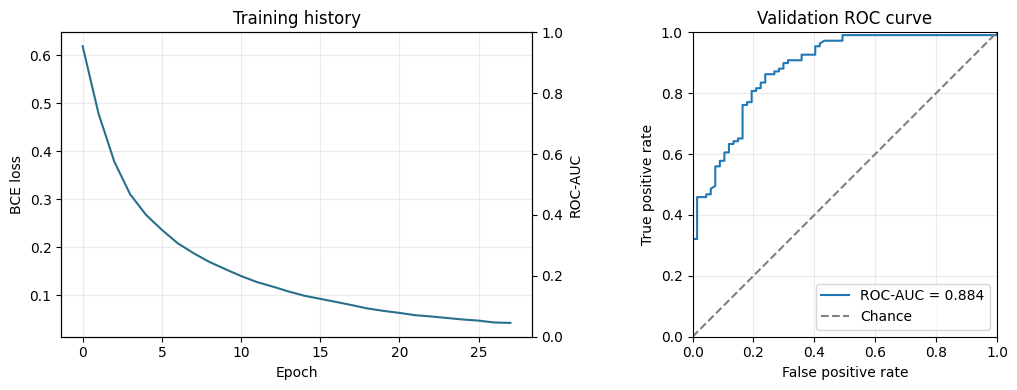

In [46]:
from sklearn.metrics import roc_curve, roc_auc_score

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Training history
axes[0].plot(train_losses, color="#286f8c", label="Training loss")
axes[0].set(title="Training history", xlabel="Epoch", ylabel="BCE loss")
axes[0].grid(alpha=0.25)

ax_auc = axes[0].twinx()
ax_auc.plot(val_aucs, color="#b36b32", label="Validation ROC-AUC")
ax_auc.set_ylabel("ROC-AUC")
ax_auc.set_ylim(0, 1)

# ROC curve
if len(np.unique(val_labels)) == 2:
    fpr, tpr, _ = roc_curve(val_labels, val_probs)
    auc = roc_auc_score(val_labels, val_probs)

    axes[1].plot(fpr, tpr, label=f"ROC-AUC = {auc:.3f}")
    axes[1].plot([0, 1], [0, 1], "--", color="gray", label="Chance")
    axes[1].legend()
else:
    axes[1].text(0.5, 0.5, "Validation has only one class",
                 ha="center", va="center")

axes[1].set(
    title="Validation ROC curve",
    xlabel="False positive rate",
    ylabel="True positive rate",
    xlim=(0, 1),
    ylim=(0, 1),
)
axes[1].grid(alpha=0.25)
axes[1].set_aspect("equal")

fig.tight_layout()
plt.show()

## 8. Evaluate once on the held-out scaffold test set

The test set gives one final estimate after the training choices are complete. ROC-AUC summarizes ranking across thresholds. Accuracy depends on a chosen threshold, here 0.5; in a discovery workflow, threshold selection should reflect the costs of false positives and false negatives and should use validation data, not the test set.

Test ROC-AUC: 0.957
Test accuracy at 0.5: 0.899
Test label counts: {0: 14, 1: 75}


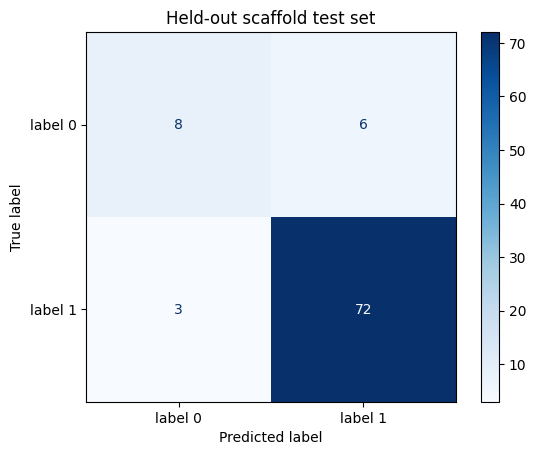

In [47]:
test_probs = predict_prob(model, X_test)
test_labels = y_test.numpy().ravel().astype(int)
test_auc = safe_auc(test_labels, test_probs)
test_preds = (test_probs >= 0.5).astype(int)
print(f'Test ROC-AUC: {test_auc:.3f}')
print(f'Test accuracy at 0.5: {accuracy_score(test_labels, test_preds):.3f}')
print('Test label counts:', pd.Series(test_labels).value_counts().sort_index().to_dict())
if len(np.unique(test_labels)) == 2:
    ConfusionMatrixDisplay(confusion_matrix(test_labels, test_preds), display_labels=['label 0','label 1']).plot(cmap='Blues', values_format='d')
    plt.title('Held-out scaffold test set'); plt.show()
else:
    print('Only one class in this scaffold test split; ROC-AUC/confusion matrix are not informative.')

## 9. Inspect predictions as hypotheses, not facts

We can inspect a few held-out molecules and their probabilities. These are model scores derived from fingerprint patterns. A high score is a hypothesis for follow-up, not a direct permeability measurement.

In [48]:
test_view = clean.iloc[test_idx][['smiles','p_np']].copy().reset_index(drop=True)
test_view['predicted_probability_label_1'] = test_probs
test_view['predicted_class_at_0.5'] = test_preds
test_view.head(12)

,smiles,p_np,predicted_probability_label_1,predicted_class_at_0.5
0,c1cc2c(cc(CC3=CNC(=NC3=O)NCCSCc3oc(cc3)CN(C)C)...,0,0.220689,0
1,O.CCN1CCN(C(=O)N[C@@H](C(=O)N[C@H]2[C@H]3SC(C)...,1,0.003012,0
2,c1ccc(C(NCCCOc2cc(CN3CCCCC3)ccc2)=O)cc1,1,0.992416,1
3,CCOC(=O)c1cncn1C(C)c2ccccc2,1,0.792196,1
4,[Cl-].CN[C@H]1CC[C@@H](c2ccc(Cl)c(Cl)c2)c3cccc...,1,0.941445,1
5,OC1C(N2CCC1)=NC(C)=C(CCN3CCC(CC3)c4c5ccc(F)cc5...,1,0.993974,1
6,CN1CCN(CC1)C2=Nc3ccccc3Cc4ccccc24,1,0.970122,1
7,CNC(=O)Oc1ccc2N(C)[C@H]3N(C)CC[C@@]3(C)c2c1,1,0.921175,1
8,C[C@]12CCC(=O)C=C1CC[C@H]3[C@@H]4CC[C@](O)(C(=...,0,0.651605,1
9,NC(=O)C1(CCN(CCCC(=O)c2ccc(F)cc2)CC1)N3CCCCC3,1,0.989842,1


## 10. Biomedical interpretation and discussion

- **Label meaning:** the dataset’s `p_np` label encodes a BBBP task, but a binary benchmark compresses assay and biological complexity into two classes.
- **Chemical series:** scaffold splitting asks whether patterns transfer to different cores; it may be substantially harder than a random split.
- **Representation:** Morgan fingerprints encode local substructures, but this MLP does not model 3D conformations, protein transporters, ionization state, plasma binding, or pharmacokinetics.
- **Uncertainty:** one train/validation/test split can vary. Repeated scaffold splits and external data are needed for robust evaluation.
- **Decision making:** CNS drug discovery balances brain exposure with potency, selectivity, toxicity, and many other properties. A permeability classifier alone cannot choose a drug candidate.

### Student exercises
1. Change the hidden layer width from 32 to 8 or 64. Compare validation and test ROC-AUC.
2. Change the threshold from 0.5 to 0.3. How do false positives and false negatives change?
3. Replace Morgan fingerprints with RDKit descriptors (e.g., MW, TPSA, logP). What information is lost or gained?
4. Compare a random split with this scaffold split. Why can random splitting overestimate performance on new chemical series?
5. Identify one experiment that would be needed to validate a high-scoring molecule.

### Summary
Backpropagation takes the error from the predicted BBBP class, propagates gradients backward through the neural network, and updates weights to reduce loss. PyTorch automates the derivatives; understanding the forward pass, loss, gradients, and split design lets us interpret what training actually did.

## References

- [DeepChem BBBP loader documentation and dataset URL](https://github.com/deepchem/deepchem/blob/master/deepchem/molnet/load_function/bbbp_datasets.py)
- [Wu et al., MoleculeNet: A Benchmark for Molecular Machine Learning](https://pmc.ncbi.nlm.nih.gov/articles/PMC5868307/)
- [PyTorch: `BCEWithLogitsLoss`](https://pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html) and [Autograd mechanics](https://pytorch.org/docs/stable/notes/autograd.html)
- Original BBBP dataset reference listed by DeepChem: Martins et al., “A Bayesian approach to in silico blood-brain barrier penetration modeling,” *Journal of Chemical Information and Modeling* (2012).